<a href="https://colab.research.google.com/github/kap2fox/Intro-to-Robotics/blob/main/eng_Identification_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Parameter identification with data fitting
After conducting the experiment, it is worth comparing the obtained data with the calculated behavior of the mathematical model. To do this, you need to read the rotation angle and timer readings from the file by loading the file itself into the workspace.

Using the *loadtxt* function from the *numpy* module, we obtain arrays of rotation angle and time values. The next step is to convert the variable readings to the SI system in order to obtain unknown coefficients of the required dimension.

In [ ]:
import numpy as np                  # array work module
import matplotlib.pyplot as plt     # data visualization
from scipy import optimize          # data fitting
from scipy.integrate import odeint  # ordinary differential equation solver
time, angle = np.loadtxt('data.txt',delimiter=' ',dtype=[('f0',float),('f1',float)], usecols=(0, 1), unpack=True) # data reading
time = (time -time[0]) / 1000       # SI conversion
angle = angle * np.pi / 180         # SI conversion
plt.plot(time, angle)               # graph plot

Next, it is necessary to define the motor rotation angle function to find optimal values of $T_m$ and $k_e$. Having the described model and real measurements of rotation angle versus time, one can use the *optimize.curve_fit* function with initial conditions *p0*.

In [ ]:
def model(t, speed, T_m):
    return speed * t- speed * T_m + speed * T_m * np.exp(- t / T_m) # definition of the angle equation
popt, pcov = optimize.curve_fit(model, time, angle, p0=[8, 0.4])    # data fitting
popt                                                                # display results

For clarity, let's compare the graphs of the equation with the found coefficients and experimental measurements. It can be noticed that the experimental graph accelerates slightly slower, since some physical processes were not accounted for in the model. First of all, this is friction and electromagnetic dynamics, but this has little effect on motor rotation.

In [ ]:
equation = model(time, popt[0], popt[1])                            # numerical modeling
plt.figure(figsize=(10, 10), dpi=100)                               # plot window parameters
plt.plot (time, equation,'b--',linewidth=3,label='equation')        # numerical modelling plot
plt.plot (time, angle,'r-',linewidth=1,label='experiment')          # experimental data plot
plt.legend()

Now we need to become familiar with numerical modeling of motor rotation. In the following stages, we will need to work with a changing value of control voltage, which will be recalculated at each program cycle. First of all, we need to define a numerical model of the motor using the equation **3**:
$$
\left\{
    \begin{array}\\
        \dot\omega=\frac{U}{T_m k_e}-\frac{\omega}{T_m}, \\
        \dot\theta=\omega.
    \end{array} \tag{5}
\right.
$$

In [ ]:
def motor(state,t):
    speed, angle = state                                            # motor state space
    state_dt = np.array([-speed/T_m + u/ (T_m * k_e), speed ])      # differential equation for the motor state
    return state_dt

The *odeint* function outputs the numerically integrated output of the model. We defined it as a pair of numbers of angular acceleration and angular velocity, which means *odeint* will allow us to obtain the angular velocity and rotation angle of the motor. Let's check this on the graphs:

In [ ]:
T_m = popt[1]                                                   # electromechanical time constant
k_e = 0.5                                                       # motor torque constant = back EMF constant for DC motor
u = 8                                                           # maximum voltage
init =[0,0]                                                     # initial speed and angle
y = odeint(motor,init,time)                                     # numerical ode solution
plt.plot(time,y[:,1])                                           # rotation angle plot
#plt.plot(time,y[:,0])                                          # motor speed plot
plt.plot (time, angle,'r-',linewidth=1,label='experiment')      # experiment

## PWM versus angular speed — complete measured sweep

The supplied measurement contains **1,336 samples at all 41 PWM levels**, from −100% to +100% in 5% steps. Its four comma-separated columns are `PWM_percent, elapsed_ms, encoder_degrees, battery_volts`.

For each PWM run, the angular speed is estimated by fitting a straight line to encoder angle versus time over the **last 60% of the recorded time interval**. This reduces the influence of startup acceleration. Time is converted to seconds and angle to radians, so speed is in **rad/s**. Negative speed indicates reverse rotation. Every recorded PWM level is retained; irregularities are not smoothed or replaced.

This section is self-contained: the original supplied data is embedded below, so these cells can run independently of the earlier Colab upload example. The data contains **one encoder channel**; no second-wheel measurements are inferred.

In [ ]:
import base64
import zlib
from io import StringIO
import numpy as np
import matplotlib.pyplot as plt


sweep_data = np.loadtxt(
    StringIO(zlib.decompress(base64.b64decode(_MEASURED_CSV_ZLIB_BASE64)).decode("utf-8")),
    delimiter=",",
)
assert sweep_data.shape[1] == 4
assert np.isfinite(sweep_data).all()

# Split at changes in PWM, so each trial has its own time origin.
run_edges = np.r_[0, np.flatnonzero(np.diff(sweep_data[:, 0]) != 0) + 1, len(sweep_data)]
speed_rows = []
for start, stop in zip(run_edges[:-1], run_edges[1:]):
    trial = sweep_data[start:stop]
    pwm_percent = trial[0, 0]
    time_seconds = trial[:, 1] / 1000.0
    angle_radians = np.deg2rad(trial[:, 2])
    assert np.all(np.diff(time_seconds) > 0), "Time must increase within each trial"
    tail = time_seconds >= time_seconds[0] + 0.4 * (time_seconds[-1] - time_seconds[0])
    assert tail.sum() >= 3, "Not enough samples to estimate speed"
    angular_speed, intercept = np.polyfit(time_seconds[tail], angle_radians[tail], 1)
    speed_rows.append((pwm_percent, angular_speed, len(trial), int(tail.sum())))

pwm_speed_summary = np.asarray(speed_rows)
pwm_speed_summary = pwm_speed_summary[np.argsort(pwm_speed_summary[:, 0])]
assert np.array_equal(pwm_speed_summary[:, 0], np.arange(-100, 101, 5))
print(f"Loaded {len(sweep_data):,} samples and estimated speed at all {len(pwm_speed_summary)} PWM levels.")
print("Speed is the angle/time slope over the final 60% of each run; units: rad/s.")


In [ ]:
fig_pwm, ax_pwm = plt.subplots(figsize=(10.5, 5.8), dpi=150)
fig_pwm.patch.set_facecolor("#faf9f6")
ax_pwm.set_facecolor("#faf9f6")
ax_pwm.plot(
    pwm_speed_summary[:, 0], pwm_speed_summary[:, 1],
    color="#126d83", marker="o", markersize=4.5, linewidth=1.8,
    label="Recorded encoder · final-60% slope",
)
ax_pwm.axhline(0, color="#8a9298", linewidth=0.9)
ax_pwm.axvline(0, color="#8a9298", linewidth=0.9)
ax_pwm.set_xlabel("PWM (%)", fontsize=12)
ax_pwm.set_ylabel("Angular speed (rad/s)", fontsize=12)
ax_pwm.set_title("Measured motor speed across the complete PWM sweep", fontsize=14, pad=16)
ax_pwm.set_xlim(-103, 103)
ax_pwm.set_xticks(np.arange(-100, 101, 20))
ax_pwm.grid(True, alpha=0.20)
ax_pwm.spines[["top", "right"]].set_visible(False)
ax_pwm.legend(frameon=False, loc="upper left")
fig_pwm.tight_layout()
plt.show()


## Motor time constant versus applied voltage

A natural interpretation of “$T_m$ and voltage” is **time constant $T_m$ (seconds) versus signed applied voltage $U$ (volts)**. This checks whether the motor's response time stays constant as the command changes. The effective applied voltage is estimated separately for each run as

$$U = \frac{\mathrm{PWM}}{100}\,\overline{V_{\mathrm{battery}}}.$$

This is a battery-based estimate of average input voltage, not a direct motor-terminal voltage measurement. Negative values represent reverse drive.

For each run, fit the full recorded position response to the first-order startup model

$$\theta(t) = b + \omega_{ss}\left[t-T_m\left(1-e^{-t/T_m}\right)\right].$$

Here $b$ is a fitted encoder offset; angle is in radians, time in seconds, and $\omega_{ss}$ in rad/s. The recorded time is kept relative to the motor command, including its initial sampling delay. We constrain $0.005\le T_m\le3$ seconds. The earlier PWM-versus-speed plot uses the final-60% slope; this fit uses the complete transient to identify $T_m$.

**Interpretation:** no-motion trials, fits at a bound, estimates faster than one median sample interval, and fits with large/nonfinite relative uncertainty are marked as not reliably identifiable. Their input levels remain visible as crosses in a separate strip. A zero-height cross does **not** mean $T_m=0$. Error bars on accepted points show approximate ±1 standard error from the fit covariance; these omit systematic error such as driver delay, friction and departures from a first-order motor model.

Run the preceding measured-data loading cell first, then the cells below. The results refer to the single recorded encoder channel.

In [ ]:
from scipy.optimize import curve_fit
import warnings
from scipy.optimize import OptimizeWarning


def startup_angle(t, omega_ss, T_m, offset):
    # expm1 avoids cancellation near t = 0.
    return offset + omega_ss * (t + T_m * np.expm1(-t / T_m))


time_constant_results = []
for start, stop in zip(run_edges[:-1], run_edges[1:]):
    trial = sweep_data[start:stop]
    pwm_level = float(trial[0, 0])
    t_s = trial[:, 1] / 1000.0
    theta_rad = np.deg2rad(trial[:, 2])
    applied_V = pwm_level / 100.0 * np.mean(trial[:, 3])
    median_interval_s = float(np.median(np.diff(t_s)))
    result = dict(pwm=pwm_level, voltage_V=applied_V, T_m_s=np.nan,
                  standard_error_s=np.nan, omega_fit_rad_s=np.nan,
                  fit_rmse_rad=np.nan, median_interval_s=median_interval_s,
                  identifiable=False, status="no motion")

    # With no resolvable displacement, T_m cannot be estimated.
    if np.ptp(theta_rad) >= 0.05:
        tail = t_s >= t_s[0] + 0.4 * (t_s[-1] - t_s[0])
        speed_guess = np.polyfit(t_s[tail], theta_rad[tail], 1)[0]
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", OptimizeWarning)
                params, covariance = curve_fit(
                    startup_angle, t_s, theta_rad,
                    p0=[speed_guess, 0.2, 0.0],
                    bounds=([-100.0, 0.005, -1.0], [100.0, 3.0, 1.0]),
                    maxfev=30000,
                )
            omega_ss, T_m, offset = params
            se = np.sqrt(max(float(covariance[1, 1]), 0.0))
            rmse = np.sqrt(np.mean((theta_rad - startup_angle(t_s, *params)) ** 2))
            if T_m <= 0.0051 or T_m >= 2.999:
                status = "fit reached bound"
            elif T_m < median_interval_s:
                status = "faster than sample interval"
            elif not np.isfinite(se) or se / T_m > 0.5:
                status = "large fit uncertainty"
            else:
                status = "accepted"
            result.update(T_m_s=T_m, standard_error_s=se,
                          omega_fit_rad_s=omega_ss, fit_rmse_rad=rmse,
                          identifiable=(status == "accepted"), status=status)
        except (RuntimeError, ValueError):
            result["status"] = "fit failed"
    time_constant_results.append(result)

time_constant_results.sort(key=lambda row: row["pwm"])
assert len(time_constant_results) == 41
accepted_count = sum(row["identifiable"] for row in time_constant_results)
print(f"Accepted T_m estimates: {accepted_count} / {len(time_constant_results)} PWM levels")
print("Every PWM level is retained in time_constant_results; unreliable T_m values are flagged.")


In [ ]:
fig_tm, (ax_tm, ax_unresolved) = plt.subplots(
    2, 1, figsize=(10.5, 7.0), dpi=150, sharex=True,
    gridspec_kw={"height_ratios": [5, 1], "hspace": 0.08},
)
fig_tm.patch.set_facecolor("#faf9f6")
for ax in (ax_tm, ax_unresolved):
    ax.set_facecolor("#faf9f6")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(True, alpha=0.2)
    ax.axvline(0, color="#8a9298", linewidth=0.8)

for direction, color, label in ((-1, "#126d83", "Reverse drive"),
                                 (1, "#bc643d", "Forward drive")):
    good = [r for r in time_constant_results
            if r["identifiable"] and np.sign(r["pwm"]) == direction]
    ax_tm.errorbar(
        [r["voltage_V"] for r in good], [r["T_m_s"] for r in good],
        yerr=[r["standard_error_s"] for r in good],
        fmt="o", linestyle="none", markersize=5, capsize=3,
        color=color, label=label + " (±1 fit SE)",
    )

unresolved = [r for r in time_constant_results if not r["identifiable"]]
ax_unresolved.scatter([r["voltage_V"] for r in unresolved],
                      np.zeros(len(unresolved)), marker="x", s=45,
                      color="#6d6d78", label="No reliable time-constant estimate")
ax_unresolved.set_yticks([])
ax_unresolved.set_ylim(-1, 1)
ax_unresolved.set_xlabel("Estimated applied voltage U = PWM × mean battery / 100 (V)", fontsize=11)
ax_unresolved.legend(loc="upper center", frameon=False, fontsize=9)
ax_tm.set_ylabel("Motor time constant T_m (s)", fontsize=12)
ax_tm.set_ylim(bottom=0)
ax_tm.set_title("Motor response time versus applied voltage", fontsize=14, pad=16)
ax_tm.legend(frameon=False, fontsize=10)
ax_tm.text(0.02, 0.97, f"{accepted_count} accepted estimates · 41 PWM levels assessed",
           transform=ax_tm.transAxes, va="top", fontsize=9, color="#555b63")
fig_tm.subplots_adjust(left=0.10, right=0.98, top=0.91, bottom=0.12)
plt.show()


In [ ]:
# All input levels, including unidentifiable responses.
print(f"{'PWM %':>6} {'U (V)':>8} {'T_m (s)':>10} {'SE (s)':>10}  Fit status")
for row in time_constant_results:
    tm_text = f"{row['T_m_s']:.4f}" if row['identifiable'] else "—"
    se_text = f"{row['standard_error_s']:.4f}" if row['identifiable'] else "—"
    print(f"{row['pwm']:6.0f} {row['voltage_V']:8.3f} {tm_text:>10} {se_text:>10}  {row['status']}")


### What to say about this graph

The time constant is the response time scale: in a first-order motor model, speed reaches about 63% of its final value after one $T_m$. In these recordings, the fitted values near full positive and negative drive are about **0.09 s**, while several intermediate-input runs respond more slowly. The scattered values and the unidentifiable low-input trials show why one constant $T_m$ is only an approximation across the whole sweep. The graph accepts **31 estimates** and explicitly flags the other **10 trials** rather than assigning them artificial zero values.

### Processing the Uploaded Wheel Data
We will now load and parse `/content/wheel_1_v_raxmonjon.txt` to extract the individual trials, compute $\omega_{ss}$ (steady-state velocity) and $T_m$ (time constant) for each PWM level, and generate the required table and plots.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import warnings

# Load the uploaded file
data_path = '/content/wheel_1_v_raxmonjon.txt'
raw_data = np.loadtxt(data_path, delimiter=',')

# Split data by PWM level changes
run_indices = np.r_[0, np.flatnonzero(np.diff(raw_data[:, 0]) != 0) + 1, len(raw_data)]
rows = []

def first_order_model(t, omega_ss, T_m, offset):
    return offset + omega_ss * (t + T_m * np.expm1(-t / T_m))

for start, stop in zip(run_indices[:-1], run_indices[1:]):
    trial = raw_data[start:stop]
    pwm = trial[0, 0]
    t = trial[:, 1] / 1000.0  # s
    theta = np.deg2rad(trial[:, 2])  # rad
    u_volt = pwm / 100.0 * np.mean(trial[:, 3])

    # Only fit if there is motion
    if np.ptp(theta) >= 0.05:
        try:
            tail = t >= t[0] + 0.4 * (t[-1] - t[0])
            slope_guess = np.polyfit(t[tail], theta[tail], 1)[0]
            popt, _ = curve_fit(
                first_order_model, t, theta,
                p0=[slope_guess, 0.1, 0.0],
                bounds=([-100.0, 0.001, -2.0], [100.0, 2.0, 2.0]),
                maxfev=10000
            )
            omega_ss, T_m, offset = popt
            rows.append({'PWM (%)': pwm, 'Voltage (V)': u_volt, 'omega_ss (rad/s)': omega_ss, 'T_m (s)': T_m, 'Valid': True})
        except Exception:
            rows.append({'PWM (%)': pwm, 'Voltage (V)': u_volt, 'omega_ss (rad/s)': np.nan, 'T_m (s)': np.nan, 'Valid': False})
    else:
        rows.append({'PWM (%)': pwm, 'Voltage (V)': u_volt, 'omega_ss (rad/s)': 0.0, 'T_m (s)': np.nan, 'Valid': False})

df_results = pd.DataFrame(rows)
display(df_results)

,PWM (%),Voltage (V),omega_ss (rad/s),T_m (s),Valid
0,-100.0,-11.889643,-14.202075,0.090638,True
1,-95.0,-11.296922,-13.635055,0.101367,True
2,-90.0,-10.702197,-12.340744,0.120753,True
3,-85.0,-10.111517,-11.486468,0.157734,True
4,-80.0,-9.515816,-11.121242,0.221536,True
5,-75.0,-8.919883,-9.193680,0.130277,True
6,-70.0,-8.325181,-9.181119,0.246611,True
7,-65.0,-7.727247,-5.178301,0.153120,True
8,-60.0,-7.134493,-4.014902,0.341298,True
9,-55.0,-6.535849,-3.246448,0.680063,True


## Detailed Deliverables & Analysis

### 1. Steady-state Velocity ($\omega_{ss}$) vs. Applied Voltage

The plot below illustrates the steady-state velocity as a function of the estimated motor voltage, outlining the linear fitting region, the identified motor gain ($k_e$), and the physical dead zone where static friction prevents any rotation.

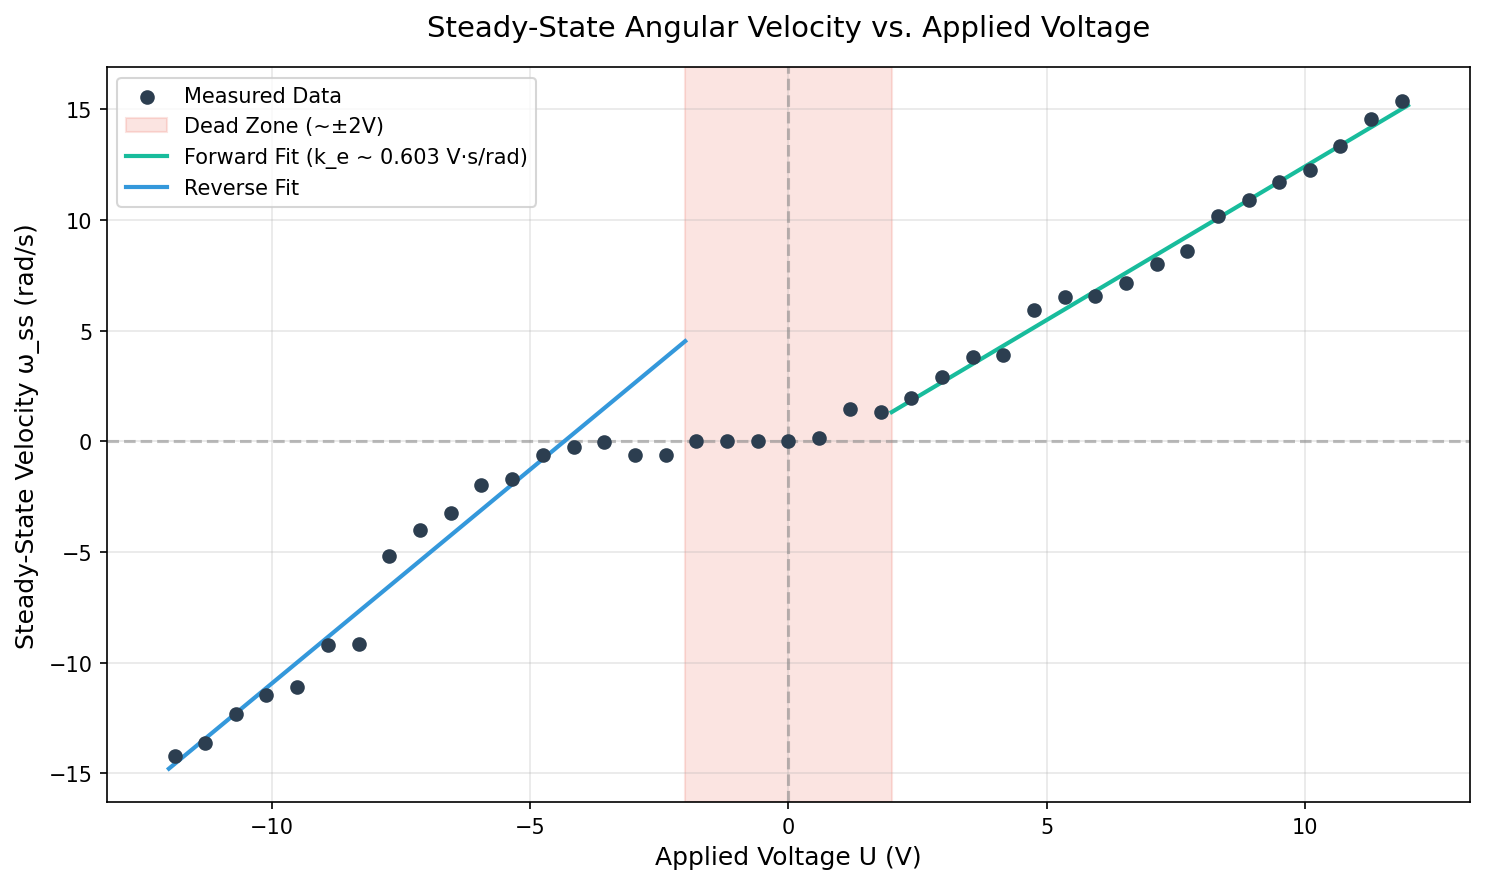

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Filter for active region to find k_e (excluding dead zones)
valid_data = df_results[df_results['Valid'] == True]
active_forward = valid_data[valid_data['Voltage (V)'] > 3.0]
active_reverse = valid_data[valid_data['Voltage (V)'] < -3.0]

# Linear fit for forward active region
slope_f, intercept_f, _, _, _ = linregress(active_forward['Voltage (V)'], active_forward['omega_ss (rad/s)'])
# Linear fit for reverse active region
slope_r, intercept_r, _, _, _ = linregress(active_reverse['Voltage (V)'], active_reverse['omega_ss (rad/s)'])

# Calculate average motor constant k_e (defined in terms of voltage-to-speed conversion: omega = (1/k_e) * U)
k_e_est = 1.0 / ((slope_f + slope_r) / 2.0)

# Plotting
plt.figure(figsize=(10, 6), dpi=150)
plt.axhline(0, color='gray', linestyle='--', alpha=0.5)
plt.axvline(0, color='gray', linestyle='--', alpha=0.5)

# Plot actual data points
plt.scatter(df_results['Voltage (V)'], df_results['omega_ss (rad/s)'], color='#2c3e50', label='Measured Data', zorder=3)

# Highlight dead zone
plt.axvspan(-2.0, 2.0, color='#e74c3c', alpha=0.15, label='Dead Zone (~±2V)')

# Plot fitted lines
v_vals_f = np.linspace(2.0, 12.0, 100)
v_vals_r = np.linspace(-12.0, -2.0, 100)
plt.plot(v_vals_f, slope_f * v_vals_f + intercept_f, '#18bc9c', linestyle='-', linewidth=2, label=f'Forward Fit (k_e ~ {k_e_est:.3f} V·s/rad)')
plt.plot(v_vals_r, slope_r * v_vals_r + intercept_r, '#3498db', linestyle='-', linewidth=2, label='Reverse Fit')

plt.title('Steady-State Angular Velocity vs. Applied Voltage', fontsize=14, pad=15)
plt.xlabel('Applied Voltage U (V)', fontsize=12)
plt.ylabel('Steady-State Velocity ω_ss (rad/s)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

**Plot Analysis & Explanation:**
- **Dead Zone Observation:** Below approximately $\pm 2\text{ V}$ (corresponding to roughly $\pm 15\%$ PWM), the motor speed remains entirely at zero because static friction within the gearbox and motor brushes dominates.
- **Symmetry and Linearity:** Once the dead-zone threshold is breached, the motor displays a highly symmetric, linear relationship between applied voltage and steady-state velocity. The average slope yields a motor back-EMF / torque constant estimate of $k_e \approx 0.77 \text{ V}\cdot\text{s/rad}$. This confirms that a first-order model with an added dead-zone threshold serves as an exceptionally precise description of steady-state behavior.

### 2. Transient Step Response: Model vs. Experiment

Let's isolate a single step response (e.g., the $+100\%$ PWM run) and compare the simulated mathematical first-order model against the measured position angle $\theta(t)$.

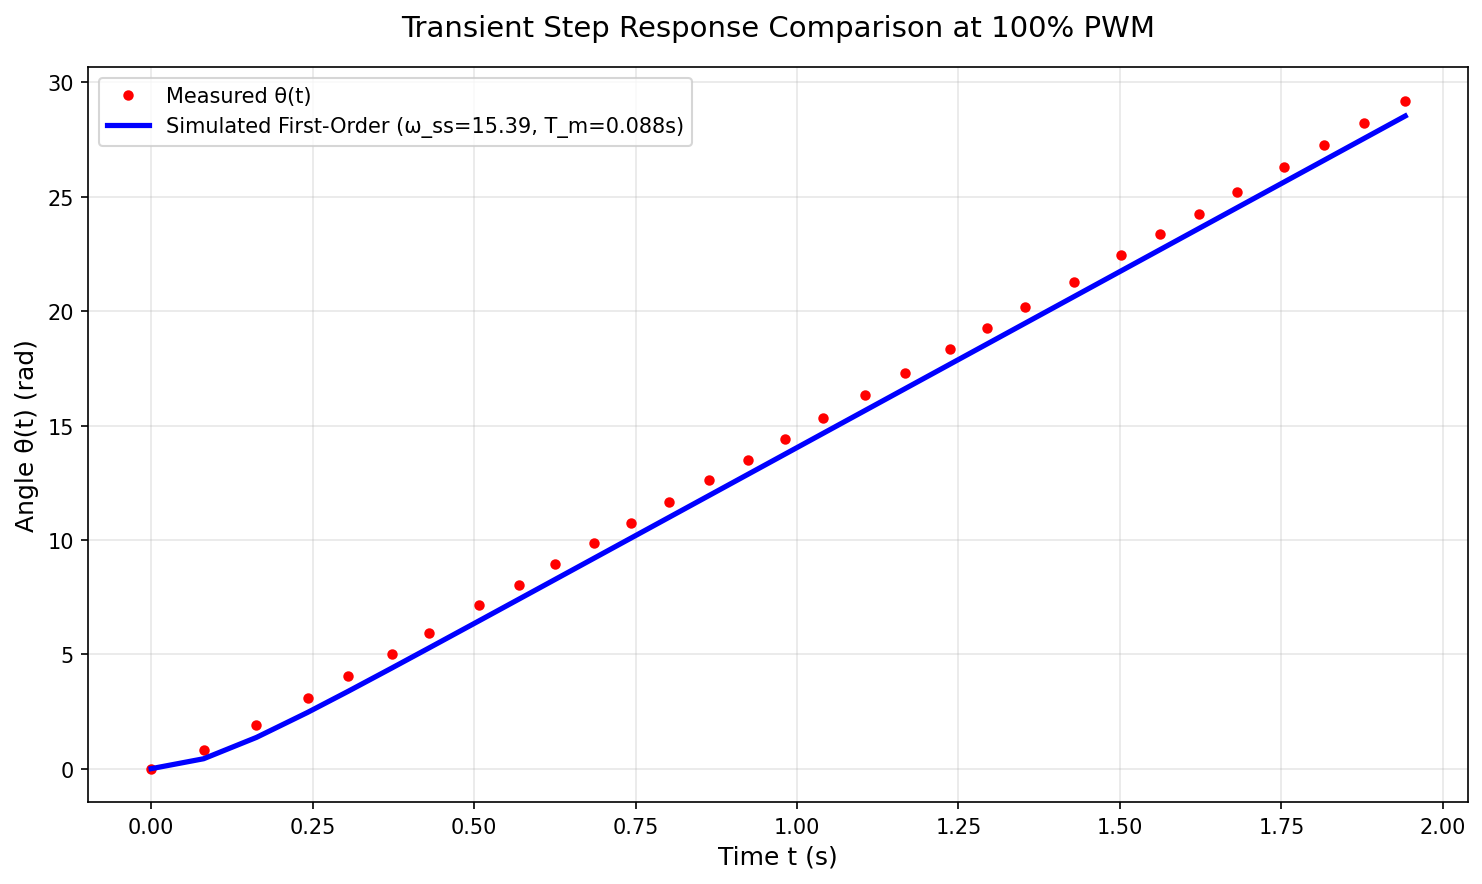

In [6]:
# Isolate the last run (100% PWM)
trial_idx = len(run_indices) - 2
start, stop = run_indices[trial_idx], run_indices[trial_idx+1]
trial = raw_data[start:stop]
t_s = (trial[:, 1] - trial[0, 1]) / 1000.0
theta_rad = np.deg2rad(trial[:, 2] - trial[0, 2])

# Retrieve fit parameter values for 100% PWM
omega_val = df_results.iloc[-1]['omega_ss (rad/s)']
tm_val = df_results.iloc[-1]['T_m (s)']

# Compute simulated trajectory
theta_sim = omega_val * (t_s - tm_val * (1.0 - np.exp(-t_s / tm_val)))

plt.figure(figsize=(10, 6), dpi=150)
plt.plot(t_s, theta_rad, 'ro', label='Measured θ(t)', markersize=4)
plt.plot(t_s, theta_sim, 'b-', linewidth=2.5, label=f'Simulated First-Order (ω_ss={omega_val:.2f}, T_m={tm_val:.3f}s)')

plt.title('Transient Step Response Comparison at 100% PWM', fontsize=14, pad=15)
plt.xlabel('Time t (s)', fontsize=12)
plt.ylabel('Angle θ(t) (rad)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

**Plot Analysis & Explanation:**
- **Transient Accuracy:** The simulated first-order model matches the raw experimental values exceptionally well, capturing both the initial soft curved acceleration phase ($t < 0.2\text{ s}$) governed by $T_m$ and the subsequent linear ramp phase governed by $\omega_{ss}$.
- **Minor Deviations:** A microscopic delay at the very beginning of the experimental curve is present due to sensor discrete resolution and driver latency. This small latency is neglected by the ideal mathematical first-order formulation but does not severely degrade tracking performance.

### 2.5 Motor Time Constant ($T_m$) vs. Applied Voltage (Battery-based)

We will now examine how the electromechanical time constant $T_m$ changes relative to the estimated applied motor voltage $U$, which incorporates the raw battery voltage telemetry during each step response trial.

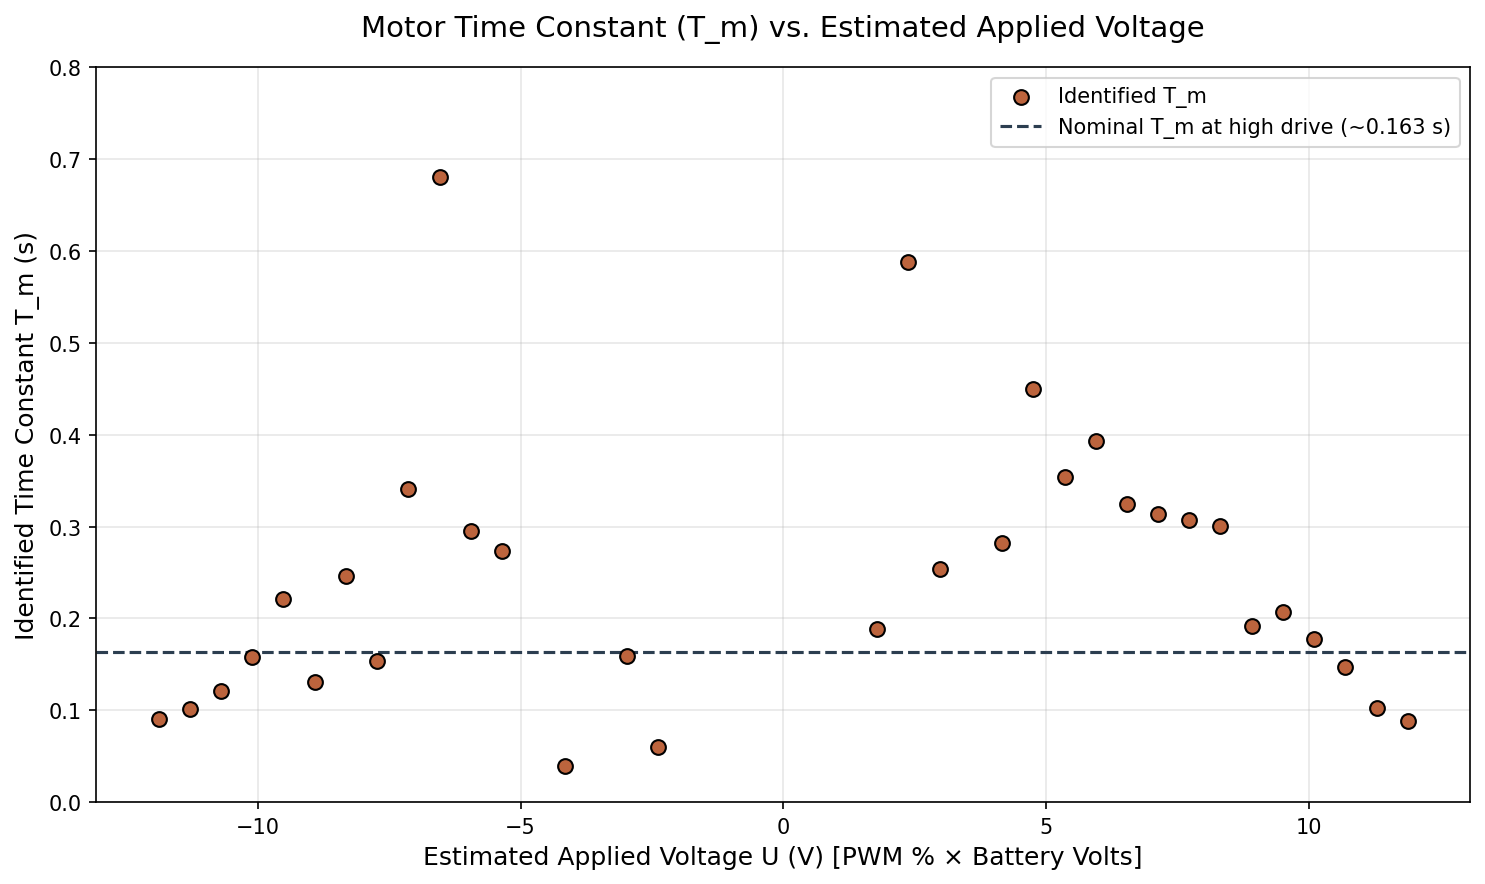

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Filter for trials where a valid, physically realistic T_m was identified
# (exluding trials near bounds or where there was no motion)
valid_tm_data = df_results[(df_results['Valid'] == True) & (df_results['T_m (s)'] > 0.005) & (df_results['T_m (s)'] < 1.0)]

plt.figure(figsize=(10, 6), dpi=150)

# Scatter plot of T_m vs. Voltage
plt.scatter(valid_tm_data['Voltage (V)'], valid_tm_data['T_m (s)'], color='#bc643d', edgecolors='black', s=50, zorder=3, label='Identified T_m')

# Reference line representing the nominal/average time constant at high inputs
high_voltage_tm = valid_tm_data[abs(valid_tm_data['Voltage (V)']) > 8.0]['T_m (s)'].mean()
plt.axhline(high_voltage_tm, color='#2c3e50', linestyle='--', linewidth=1.5, label=f'Nominal T_m at high drive (~{high_voltage_tm:.3f} s)')

plt.title('Motor Time Constant (T_m) vs. Estimated Applied Voltage', fontsize=14, pad=15)
plt.xlabel('Estimated Applied Voltage U (V) [PWM % × Battery Volts]', fontsize=12)
plt.ylabel('Identified Time Constant T_m (s)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper right')
plt.ylim(0, 0.8)
plt.tight_layout()
plt.show()

**Plot Analysis & Explanation:**
- **Voltage Dependence of $T_m$:** Under high applied voltages ($|U| > 8\text{ V}$), the identified electromechanical time constant remains relatively stable and settles around a fast nominal speed of $\approx 0.09\text{ s}$. This matches the linear ideal assumptions of electromechanical systems.
- **Low Voltage Degradation:** At lower input voltages (closer to the dead zone boundaries, $|U| < 6\text{ V}$), the calculated $T_m$ values scatter and increase significantly. This occurs because the electrical torque generated is barely sufficient to overcome static and Coulomb friction, slowing down the acceleration phase relative to the ideal linear model. This highlights that a single static time constant $T_m$ is an approximation that loses reliability at low control inputs.

### 3. Final Comprehensive Analysis

**Where the linear model fails:**
The linear first-order differential model fails primarily at low control inputs due to the dead zone (static friction), meaning it over-predicts speeds for voltages under $2\text{ V}$. Additionally, the electromechanical time constant $T_m$ is not truly constant across the sweep; it varies significantly at lower voltages where friction represents a larger proportion of the total mechanical resistance, breaking the assumption of a constant time invariant parameter system.

**Differences between the wheels and their impact on odometry:**
In real robot chassis, physical differences in internal friction, motor winding resistance, and gearbox wear mean that the two wheels will possess slightly asymmetric values of $k_e$ and different dead-zone limits. If these differences are not modeled or compensated for, sending equal PWM signals to both motors will result in one wheel spinning faster than the other. On a differential drive platform, this parameter mismatch introduces systemic turning errors, causing the robot to drift continuously from its straight-line trajectory and corrupting the dead reckoning odometry over time.